### Recognition memory analysis


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


base_dir = Path("/Users/liuq13/project-SPCD/beh_raw")

# load common plot configurations
import plot_config

In [2]:
# normalize the resp col 
def norm_resp(s: pd.Series) -> pd.Series:
    s = s.astype("string")  # preserves missing better than astype(str)
    s = s.str.strip()

    # remove surrounding quotes if they exist (handles "'right'" and '"right"')
    s = s.str.strip("'").str.strip('"')

    # normalize case
    s = s.str.lower()

    # map common “missing-ish” values to NA
    s = s.replace({"": pd.NA, "nan": pd.NA, "none": pd.NA, "na": pd.NA})
    return s

In [3]:
results = []

for sub_dir in sorted(base_dir.glob("sub-*")):
    csv_files = list(sub_dir.glob("*RecognitionTrials.csv"))
    if not csv_files:
        continue

    df = pd.read_csv(csv_files[0])

    # trial-level accuracy
    df["accuracy"] = (
        df["correct"].astype(str) == df["key_resp.keys_raw"].astype(str)
    ).astype(float)

    correct_norm = norm_resp(df["correct"])
    resp_norm    = norm_resp(df["key_resp.keys_raw"])

    df["accuracy"] = (correct_norm == resp_norm).astype("float")
    df.loc[correct_norm.isna() | resp_norm.isna(), "accuracy"] = np.nan  # keep missing as NaN
    
    # drop trials with missing response or RT
    df = df.dropna(subset=["accuracy", "key_resp.rt_mean"])

    summary = (
        df.groupby("pair")
          .agg(
              mean_accuracy=("accuracy", "mean"),
              mean_rt=("key_resp.rt_mean", "mean"),
              n_trials=("accuracy", "count")
          )
          .reset_index()
    )

    summary["subject"] = sub_dir.name
    results.append(summary)

final_df = pd.concat(results, ignore_index=True)


EXCLUDE_SUBJECTS = ['sub-19', 'sub-33']
final_df = final_df[~final_df['subject'].isin(EXCLUDE_SUBJECTS)]


In [4]:
df = final_df.copy()
df["pair"] = df["pair"].astype(int)

pair_to_group = {1:1, 4:1, 2:2, 5:2, 3:3, 6:3}
df["group"] = df["pair"].map(pair_to_group)
df

,pair,mean_accuracy,mean_rt,n_trials,subject,group
0,1,1.0,1.118919,6,sub-01,1
1,2,1.0,1.287103,6,sub-01,2
2,3,1.0,0.937854,6,sub-01,3
3,4,1.0,1.084695,5,sub-01,1
4,5,1.0,1.066127,6,sub-01,2
...,...,...,...,...,...,...
199,2,1.0,0.620136,6,sub-41,2
200,3,1.0,0.660533,6,sub-41,3
201,4,1.0,0.663710,6,sub-41,1
202,5,1.0,0.631087,6,sub-41,2


Next we collapse duplicated entries to one row per subject * group

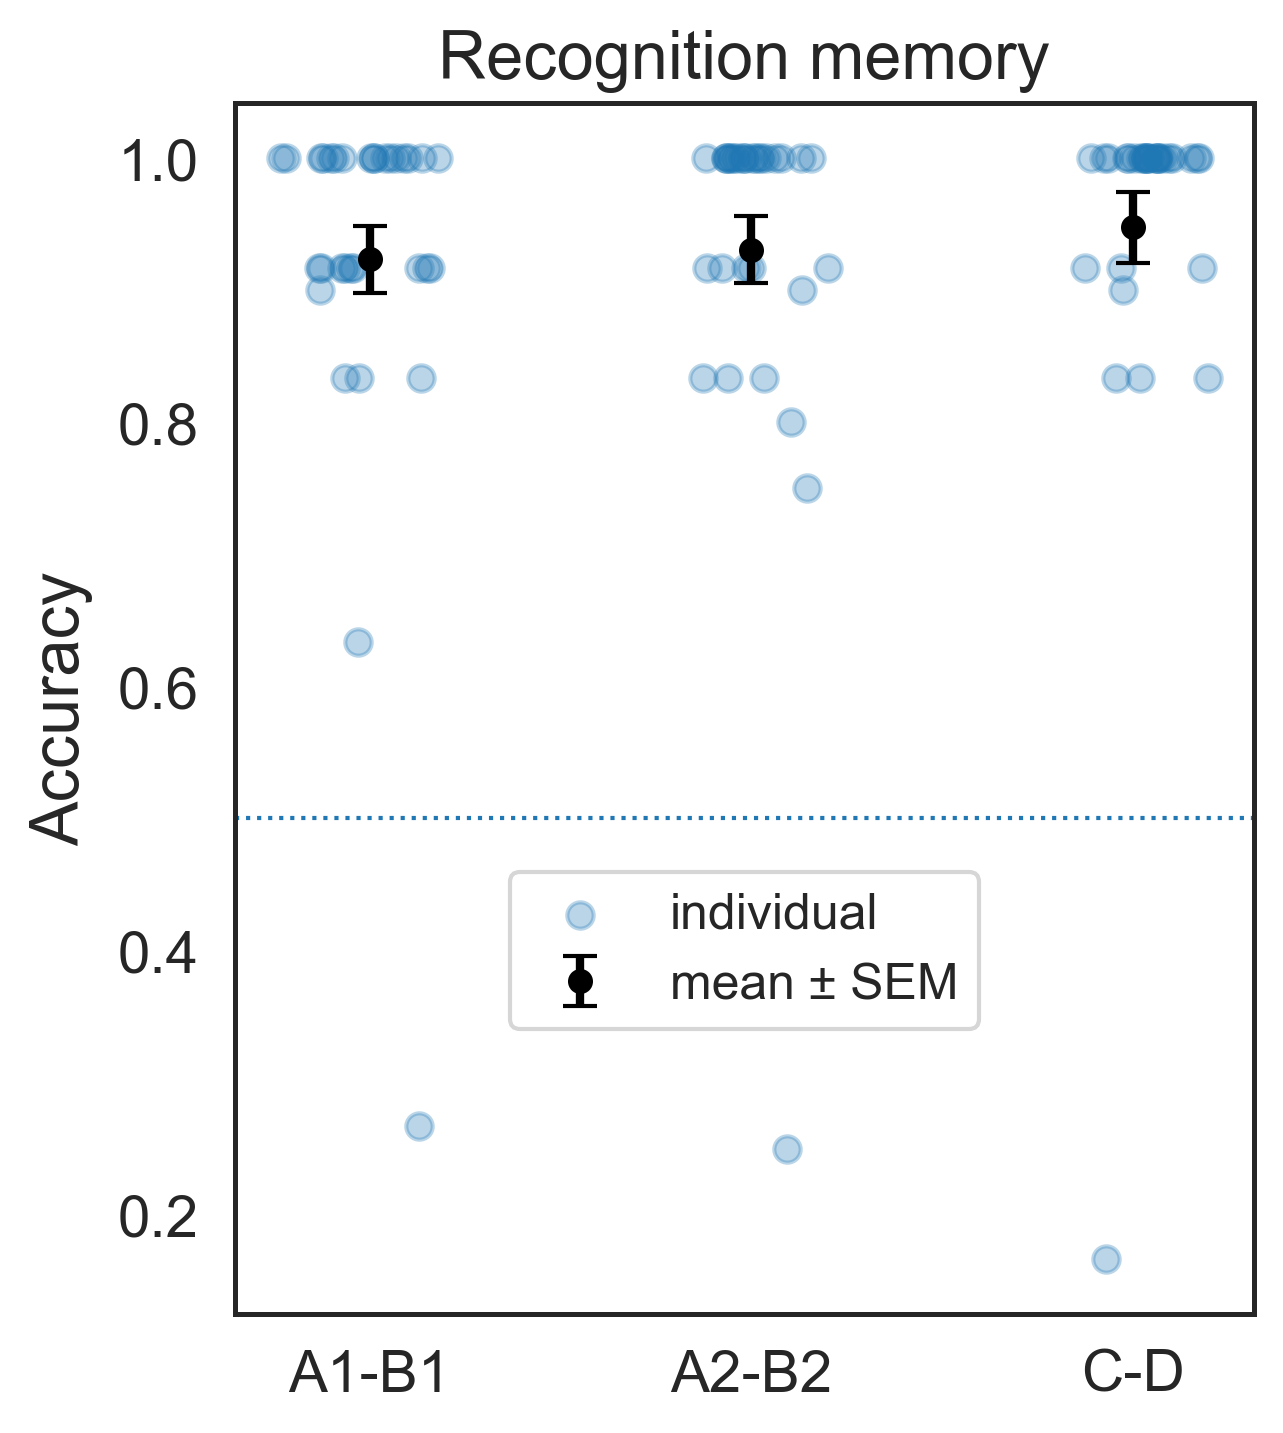

In [5]:
# collapse to one row per subject × group ---
df_sub = (
    df.groupby(["subject", "group"], as_index=False)
      .agg(mean_accuracy=("mean_accuracy", "mean"))   # average across the two pairs
)

# group-level stats (across subjects)
group_order = [1, 2, 3]
group_stats = (
    df_sub.groupby("group")["mean_accuracy"]
          .agg(mean="mean", sem="sem", n="count")
          .reindex(group_order)
          .reset_index()
)

x_centers = np.arange(len(group_order))
x_points = df_sub["group"].map({g: i for i, g in enumerate(group_order)}).to_numpy()

# --- plotting ---
fig, ax = plt.subplots(figsize=(4.5, 5))

rng = np.random.default_rng(0)
x_jitter = rng.normal(0, 0.1, size=len(df_sub))

ax.scatter(
    x_points + x_jitter,
    df_sub["mean_accuracy"],
    alpha=0.3,
    s=40,
    label="individual"
)

ax.errorbar(
    x_centers,
    group_stats["mean"],
    yerr=group_stats["sem"],
    fmt="o",
    markersize=5,
    capsize=4,
    linewidth=2,
    color="black",
    label="mean ± SEM"
)

ax.axhline(0.5, linestyle="dotted", linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Accuracy")
ax.set_title("Recognition memory")

ax.legend(loc="center", bbox_to_anchor=(0.5, 0.3), frameon=True)

group_labels = {1: "A1-B1", 2: "A2-B2", 3: "C-D"}
plt.xticks(ticks=x_centers, labels=[group_labels[g] for g in group_order])

plt.tight_layout()
plt.savefig("../plots/recognition_accuracy.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [7]:
from scipy.stats import friedmanchisquare

# df from earlier step: columns = subject, group, mean_accuracy

wide = (
    df_sub
    .pivot(index="subject", columns="group", values="mean_accuracy")
    .dropna()  # subjects must have all 3 groups
)

# ensure group order 1,2,3
g1 = wide[1].to_numpy()
g2 = wide[2].to_numpy()
g3 = wide[3].to_numpy()


In [8]:
stat, p = friedmanchisquare(g1, g2, g3)

print(f"Friedman test: χ²(2) = {stat:.3f}, p = {p:.4g}")


Friedman test: χ²(2) = 2.203, p = 0.3324
